# Experiment 024: 7B extended MC-SFT analysis

Six completed 024 arms:

- base model to MMLU MC-SFT for 16 passes, seeds 0 to 2
- seed matched GSM8K-SFT checkpoint to MMLU MC-SFT for 16 passes, seeds 0 to 2

The two registered comparisons answer different questions. Base p16 is compared with base p8 to test whether doubling the supervised MMLU budget helps. Warm p16 is compared with smooth 1000 step GRPO from the same seed matched GSM8K-SFT start to compare the two longer training routes.

The warm p8 comparison is kept descriptive. Only seed 0 has the same preparation checkpoint in 015 and 024. Each SFT budget also has its own linear decay schedule, so the budget result is about each method as practised rather than exposure alone.

In [1]:
# load the completed runs and the registered references
import json
import math
import sys
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
import numpy as np
import pandas as pd
from IPython.display import display
get_ipython().run_line_magic('matplotlib', 'inline')

ROOT = Path.cwd()
while not (ROOT / 'config.py').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / 'config.py').exists():
    raise FileNotFoundError('repository root containing config.py was not found')
sys.path.insert(0, str(ROOT))

from analysis.plotting import heatmap_text_color
from analysis.stats import align_pred_rows
from data.subjects import TIERS as VALIDATED_TIERS

RES = ROOT / 'results'
FIG = ROOT / 'analysis' / 'figures' / '024_1'
FIG.mkdir(parents=True, exist_ok=True)

SEEDS = (0, 1, 2)
TIERS = ['easy', 'medium', 'hard']
GROUPS = TIERS + ['overall']
TIER_LOOKUP = {
    subject: tier
    for tier, subjects in VALIDATED_TIERS.items()
    for subject in subjects
}
SUBJECTS = [
    subject
    for tier in TIERS
    for subject in VALIDATED_TIERS[tier]
]

NEW_PATHS = {
    'base p16': {
        seed: RES / f'024_p16_COLAB_FULL_B7_sft_only_seed{seed}'
        for seed in SEEDS
    },
    'warm p16': {
        seed: RES / f'024_wsft_p16_COLAB_FULL_B7_sft_only_seed{seed}'
        for seed in SEEDS
    },
}
REF_PATHS = {
    'base p8': {
        seed: RES / f'014_p8_COLAB_FULL_B7_sft_only_seed{seed}'
        for seed in SEEDS
    },
    'warm p8': {
        seed: RES / f'015_wsft_COLAB_FULL_B7_sft_only_seed{seed}'
        for seed in SEEDS
    },
    'smooth GRPO': {
        seed: RES / f'022_smooth_B7_seed{seed}_step1000'
        for seed in SEEDS
    },
}

COLORS = {
    'base p8': '#4C78A8',
    'base p16': '#54A24B',
    'warm p8': '#B279A2',
    'warm p16': '#E45756',
    'smooth GRPO': '#F58518',
    'probe': '#79706E',
}
TIER_COLORS = {
    'easy': '#59A14F',
    'medium': '#F28E2B',
    'hard': '#E15759',
    'overall': '#4C4C4C',
}

plt.style.use('seaborn-v0_8-whitegrid')

def jload(path):
    with open(path) as handle:
        return json.load(handle)

def jsonl(path):
    with open(path) as handle:
        rows = [json.loads(line) for line in handle if line.strip()]
    return [
        {**row, 'tier': row.get('tier', TIER_LOOKUP[row['subject']])}
        for row in rows
    ]

def save(fig, name):
    fig.savefig(FIG / f'{name}.png', dpi=300, bbox_inches='tight')
    print('saved', name)

def load_sft(path, include_train=False):
    output = {
        'eval': jload(path / 'sft_eval.json'),
        'probe': jload(path / 'sft_logprob.json'),
        'preds': jsonl(path / 'sft_preds.jsonl'),
        'probe_preds': jsonl(path / 'sft_logprob_preds.jsonl'),
        'manifest': jload(path / 'manifest.json'),
    }
    if include_train:
        output.update({
            'train': jload(path / 'sft_trainlog.json'),
            'eval_manifest': jload(path / 'sft_eval_manifest.json'),
            'source': jload(path / 'source_binding.json'),
            'eval_binding': jload(path / 'sft_eval_binding.json'),
            'log': (path / 'run.log').read_text(),
        })
    return output

def load_grpo(path):
    return {
        'eval': jload(path / 'grpo_eval.json'),
        'probe': jload(path / 'grpo_logprob.json'),
        'preds': jsonl(path / 'grpo_preds.jsonl'),
        'probe_preds': jsonl(path / 'grpo_logprob_preds.jsonl'),
    }

def accuracy(rows):
    return float(np.mean([bool(row['correct']) for row in rows]))

def nonfinite_paths(value, path='root'):
    found = []
    if isinstance(value, dict):
        for key, item in value.items():
            found.extend(nonfinite_paths(item, f'{path}/{key}'))
    elif isinstance(value, list):
        for index, item in enumerate(value):
            found.extend(nonfinite_paths(item, f'{path}/{index}'))
    elif isinstance(value, float) and not math.isfinite(value):
        found.append(path)
    return found

NEW = {
    condition: {
        seed: load_sft(path, include_train=True)
        for seed, path in paths.items()
    }
    for condition, paths in NEW_PATHS.items()
}
REF = {
    'base p8': {
        seed: load_sft(path)
        for seed, path in REF_PATHS['base p8'].items()
    },
    'warm p8': {
        seed: load_sft(path)
        for seed, path in REF_PATHS['warm p8'].items()
    },
    'smooth GRPO': {
        seed: load_grpo(path)
        for seed, path in REF_PATHS['smooth GRPO'].items()
    },
}
REGISTERED = jload(RES / '024_comparison_summary.json')

print('loaded all 024 arms and their registered references')
print('figures ->', FIG)

loaded all 024 arms and their registered references
figures -> /Users/oleggastov/Desktop/University UK/0006_City n St Georges Universities/003_Projects/INM363-IndividualProject-Dissertation/001_Code/analysis/figures/024_1


## 1. Completion and run health

These checks run before any result is plotted. They cover all 245 SFT updates, the registered linear schedule, both evaluation modes, hardware, precision, fallback settings, prediction counts, finite values and interruption markers.

In [2]:
# verify all six runs before using their results
health_rows = []
bad_terms = ['traceback', 'out of memory', 'protocol abort', 'keyboardinterrupt']

assert REGISTERED['binding'] is True
assert REGISTERED['complete_seeds'] == list(SEEDS)

for condition, runs in NEW.items():
    expected_variant = 'base' if condition == 'base p16' else 'warm'
    for seed, data in runs.items():
        train_rows = [
            row for row in data['train']
            if 'loss' in row and 'step' in row
        ]
        steps = [row['step'] for row in train_rows]
        learning_rates = np.asarray([
            row['learning_rate'] for row in train_rows
        ])
        manifest = data['manifest']
        config = manifest['config']
        invalid = nonfinite_paths(data['train'])
        invalid += nonfinite_paths(data['eval'])
        invalid += nonfinite_paths(data['probe'])

        assert steps == list(range(1, 246))
        assert len(set(steps)) == 245
        assert np.isclose(learning_rates[0], 1e-4)
        assert np.all(np.diff(learning_rates) <= 1e-12)
        assert learning_rates[-1] <= 5e-7
        assert data['eval']['n_items'] == 1884
        assert data['probe']['n_items'] == 1884
        assert len(data['preds']) == 1884
        assert len(data['probe_preds']) == 1884
        assert data['eval_manifest']['completed'] is True
        assert data['eval_manifest']['seed_override'] == seed
        assert data['source']['variant'] == expected_variant
        assert data['source']['seed'] == seed
        assert manifest['model_id'] == 'Qwen/Qwen2.5-7B'
        assert manifest['seed'] == seed
        assert manifest['resolved_dtype'] == 'bfloat16'
        assert 'A100-SXM4-80GB' in manifest['gpu']['device']
        assert config['train']['max_steps'] == 245
        assert config['train']['sft_data'] == 'mmlu_mc'
        assert config['train']['sft_batch_size'] == 4
        assert config['train']['sft_grad_accum'] == 4
        assert config['exec']['gradient_checkpointing'] is False
        assert config['exec']['allow_oom_fallback'] is False
        assert config['eval']['skip_generative'] is True
        assert set(data['eval_binding']) == {
            'adapter_model.safetensors',
            'adapter_config.json',
            'adapter_base.json',
        }
        assert all(
            isinstance(value, str) and len(value) == 64
            for value in data['eval_binding'].values()
        )
        assert not invalid
        assert not any(term in data['log'].lower() for term in bad_terms)

        health_rows.append({
            'condition': condition,
            'seed': seed,
            'steps': len(train_rows),
            'first LR': learning_rates[0],
            'last LR': learning_rates[-1],
            'generative items': data['eval']['n_items'],
            'probe items': data['probe']['n_items'],
            'format compliance': data['eval']['format_compliance'],
            'peak VRAM GB': manifest['gpu']['peak_vram_gb'],
            'train minutes': manifest['timings_sec']['sft_train'] / 60,
            'eval minutes': data['eval_manifest']['timings_sec']['sft_eval'] / 60,
            'git commit': manifest['git']['commit'][:8],
        })

health_tbl = pd.DataFrame(health_rows).set_index(['condition', 'seed'])
display(health_tbl.round(4))
print('all six runs passed the completion checks')

steps  first LR  last LR  generative items  probe items  \
condition seed                                                            
base p16  0       245    0.0001      0.0              1884         1884   
          1       245    0.0001      0.0              1884         1884   
          2       245    0.0001      0.0              1884         1884   
warm p16  0       245    0.0001      0.0              1884         1884   
          1       245    0.0001      0.0              1884         1884   
          2       245    0.0001      0.0              1884         1884   

                format compliance  peak VRAM GB  train minutes  eval minutes  \
condition seed                                                                 
base p16  0                   1.0        30.665         5.8262        5.2950   
          1                   1.0        30.665         5.8715        5.3799   
          2                   1.0        30.683         5.2680        5.4201   
warm p16  0                   1.0        26.785         5.1260        5.4024   
          1                   1.0        26.785         5.2596        5.5520   
          2                   1.0        26.785         5.2155        5.5430   

               git commit  
condition seed             
base p16  0      f6257229  
          1      0c274e7e  
          2      0c274e7e  
warm p16  0      f6257229  
          1      0c274e7e  
          2      0c274e7e

all six runs passed the completion checks


## 2. Supervised training behaviour

saved fig01_training_health


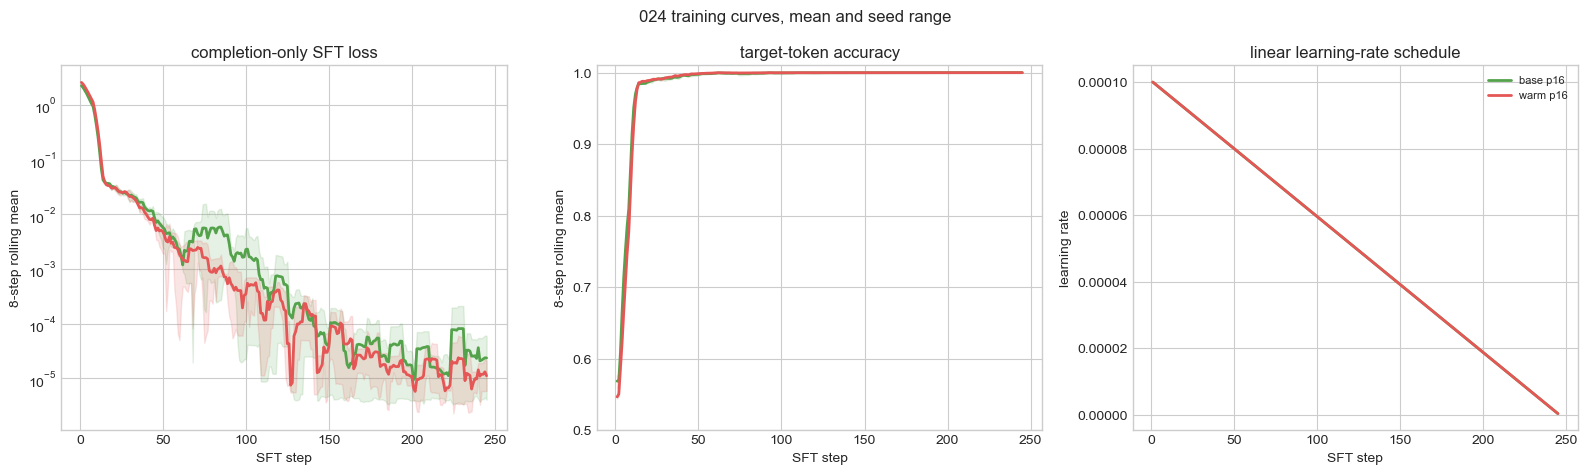

In [3]:
# compare the loss, target token accuracy and learning rate across seeds
train_rows = []
for condition, runs in NEW.items():
    for seed, data in runs.items():
        for row in data['train']:
            if 'loss' not in row or 'step' not in row:
                continue
            train_rows.append({
                'condition': condition,
                'seed': seed,
                'step': row['step'],
                'loss': row['loss'],
                'token accuracy': row['mean_token_accuracy'],
                'learning rate': row['learning_rate'],
            })
train_tbl = pd.DataFrame(train_rows)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for condition in NEW:
    subset = train_tbl[train_tbl['condition'] == condition]
    for metric, ax in [
        ('loss', axes[0]),
        ('token accuracy', axes[1]),
        ('learning rate', axes[2]),
    ]:
        pivot = subset.pivot(index='step', columns='seed', values=metric)
        smooth = pivot if metric == 'learning rate' else pivot.rolling(8, min_periods=1).mean()
        mean = smooth.mean(axis=1)
        low = smooth.min(axis=1)
        high = smooth.max(axis=1)
        ax.plot(
            mean.index,
            mean,
            color=COLORS[condition],
            lw=2,
            label=condition,
        )
        ax.fill_between(
            mean.index,
            low,
            high,
            color=COLORS[condition],
            alpha=0.15,
        )

axes[0].set_yscale('log')
axes[0].set_title('completion-only SFT loss')
axes[0].set_ylabel('8-step rolling mean')
axes[1].set_ylim(0.5, 1.01)
axes[1].set_title('target-token accuracy')
axes[1].set_ylabel('8-step rolling mean')
axes[2].set_title('linear learning-rate schedule')
axes[2].set_ylabel('learning rate')
for ax in axes:
    ax.set_xlabel('SFT step')
axes[2].legend(fontsize=8)
fig.suptitle('024 training curves, mean and seed range')
fig.tight_layout()
save(fig, 'fig01_training_health')
plt.show()

## 3. Registered comparisons

The shaded area is the registered plus or minus 2 percentage point equivalence region. Intervals are paired bootstrap intervals over the same 1,884 items. The printed classifications use the binding Holm-gated rule from the experiment, not the interval alone.

In [4]:
# collect the registered effects and exact endpoint values
effect_rows = []
endpoint_rows = []

for arm in REGISTERED['arms']:
    seed = arm['seed']
    for key, label in [
        ('base_budget', 'base p16 minus base p8'),
        ('warm_vs_smooth_grpo', 'warm p16 minus smooth GRPO'),
    ]:
        values = arm[key]
        effect_rows.append({
            'comparison': label,
            'seed': seed,
            'reference': values['reference_acc'],
            'new': values['new_acc'],
            'delta': values['delta'],
            'ci low': values['ci'][0],
            'ci high': values['ci'][1],
            'raw p': values['p_raw'],
            'Holm p': values['holm_p'],
            'classification': values['category'],
        })
    endpoint_rows.extend([
        {
            'comparison': 'base budget',
            'seed': seed,
            'endpoint': 'base p8',
            'accuracy': arm['base_budget']['reference_acc'],
        },
        {
            'comparison': 'base budget',
            'seed': seed,
            'endpoint': 'base p16',
            'accuracy': arm['base_budget']['new_acc'],
        },
        {
            'comparison': 'warm route',
            'seed': seed,
            'endpoint': 'smooth GRPO',
            'accuracy': arm['warm_vs_smooth_grpo']['reference_acc'],
        },
        {
            'comparison': 'warm route',
            'seed': seed,
            'endpoint': 'warm p16',
            'accuracy': arm['warm_vs_smooth_grpo']['new_acc'],
        },
    ])

effect_tbl = pd.DataFrame(effect_rows)
endpoint_tbl = pd.DataFrame(endpoint_rows)
display(effect_tbl.set_index(['comparison', 'seed']).round(6))
print('base budget common reading:', REGISTERED['common_readings']['base_budget'])
print('warm route common reading:', REGISTERED['common_readings']['warm_vs_smooth_grpo'])

,,reference,new,delta,ci low,ci high,raw p,Holm p,classification
comparison,seed,,,,,,,,
base p16 minus base p8,0,0.786093,0.782909,-0.003185,-0.011677,0.005308,0.550413,0.914042,equivalent
warm p16 minus smooth GRPO,0,0.807856,0.778132,-0.029724,-0.045117,-0.014331,0.000194,0.000583,material decline
base p16 minus base p8,1,0.780255,0.783970,0.003715,-0.004777,0.012208,0.457021,0.914042,equivalent
warm p16 minus smooth GRPO,1,0.801486,0.781847,-0.019639,-0.035563,-0.004246,0.015730,0.015730,inconclusive
base p16 minus base p8,2,0.784501,0.778662,-0.005839,-0.014331,0.003185,0.228400,0.685201,equivalent
warm p16 minus smooth GRPO,2,0.797771,0.772293,-0.025478,-0.040870,-0.009554,0.001792,0.003584,material decline


base budget common reading: equivalent
warm route common reading: mixed or inconclusive, report arm by arm


saved fig02_registered_effects


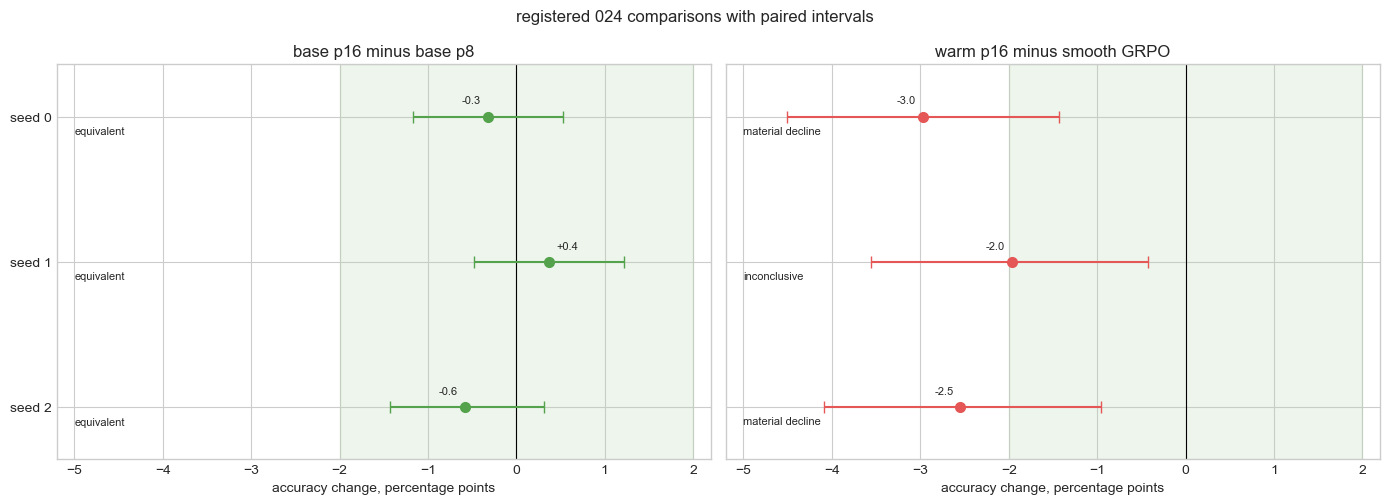

In [5]:
# plot the binding effect estimates on one shared scale
comparisons = [
    'base p16 minus base p8',
    'warm p16 minus smooth GRPO',
]
fig, axes = plt.subplots(1, 2, figsize=(14, 5.1), sharex=True, sharey=True)

for ax, comparison in zip(axes, comparisons):
    table = effect_tbl.query('comparison == @comparison').sort_values('seed')
    y = np.arange(len(table))
    values = table['delta'].to_numpy() * 100
    errors = np.vstack([
        values - table['ci low'].to_numpy() * 100,
        table['ci high'].to_numpy() * 100 - values,
    ])
    color = COLORS['base p16'] if comparison.startswith('base') else COLORS['warm p16']
    ax.axvspan(-2, 2, color='#B9D8B4', alpha=0.25)
    ax.axvline(0, color='black', lw=0.8)
    ax.errorbar(
        values,
        y,
        xerr=errors,
        fmt='o',
        capsize=4,
        color=color,
        markersize=7,
    )
    for position, (_, row) in zip(y, table.iterrows()):
        ax.annotate(
            row['classification'], (-5.0, position), xytext=(0, -7),
            textcoords='offset points', ha='left', va='top', fontsize=8,
        )
        ax.annotate(
            f"{row['delta'] * 100:+.1f}", (row['delta'] * 100, position), xytext=(5 if row['delta'] >= 0 else -5, 8),
            textcoords='offset points', ha='left' if row['delta'] >= 0 else 'right',
            va='bottom', fontsize=8,
        )
    ax.margins(y=0.18)
    ax.set_yticks(y)
    ax.set_yticklabels([f'seed {seed}' for seed in table['seed']])
    ax.set_xlim(-5.2, 2.2)
    ax.set_xlabel('accuracy change, percentage points')
    ax.set_title(comparison)

axes[0].invert_yaxis()
fig.suptitle('registered 024 comparisons with paired intervals')
fig.tight_layout()
save(fig, 'fig02_registered_effects')
plt.show()

saved fig03_matched_endpoints


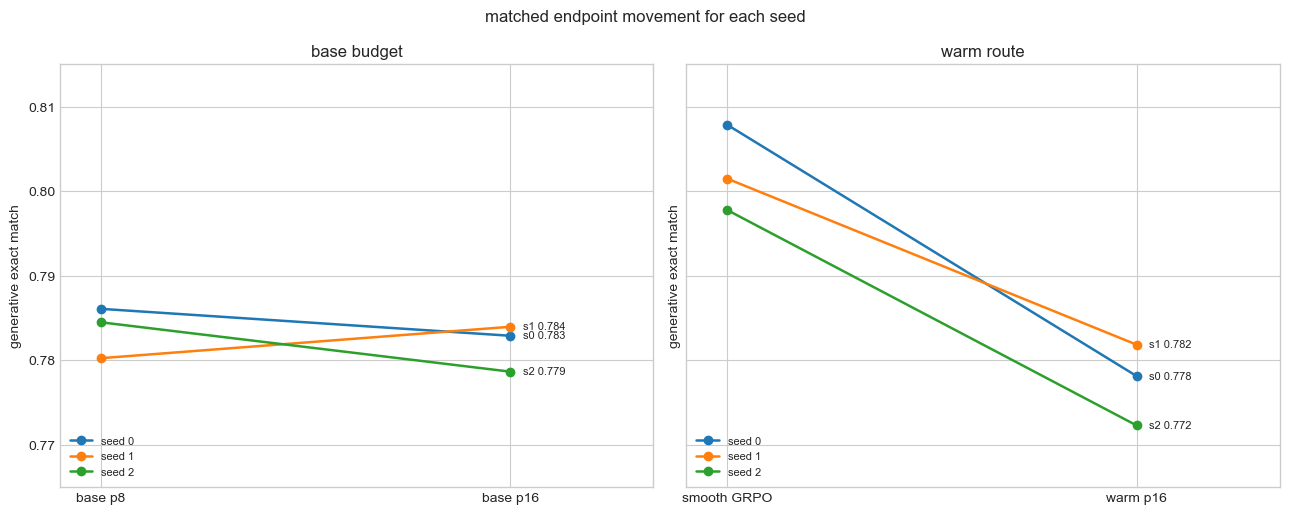

In [6]:
# show each seed moving from its matched reference to the new endpoint
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), sharey=True)
panel_specs = [
    ('base budget', ['base p8', 'base p16']),
    ('warm route', ['smooth GRPO', 'warm p16']),
]

for ax, (comparison, endpoint_order) in zip(axes, panel_specs):
    table = endpoint_tbl.query('comparison == @comparison')
    for seed in SEEDS:
        values = (
            table.query('seed == @seed')
            .set_index('endpoint')
            .loc[endpoint_order, 'accuracy']
            .to_numpy()
        )
        ax.plot(
            [0, 1],
            values,
            marker='o',
            lw=1.8,
            label=f'seed {seed}',
        )
        ax.text(1.03, values[1], f's{seed} {values[1]:.3f}', va='center', fontsize=8)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(endpoint_order)
    ax.set_xlim(-0.1, 1.35)
    ax.set_ylabel('generative exact match')
    ax.set_title(comparison)
    ax.legend(fontsize=8, loc='lower left')

axes[0].set_ylim(0.765, 0.815)
fig.suptitle('matched endpoint movement for each seed')
fig.tight_layout()
save(fig, 'fig03_matched_endpoints')
plt.show()

## 4. Tier pattern

The same comparison is split by the registered easy, medium and hard tiers. Overall is included at the right so the tier result can be read beside the headline effect.

group                              easy  medium    hard  overall
comparison                 seed                                 
base p16 minus base p8     0    -0.0080 -0.0016  0.0051  -0.0032
                           1     0.0011  0.0131 -0.0051   0.0037
                           2    -0.0148  0.0016  0.0025  -0.0058
warm p16 minus smooth GRPO 0    -0.0159  0.0016 -0.1086  -0.0297
                           1    -0.0046  0.0066 -0.0934  -0.0196
                           2    -0.0148 -0.0131 -0.0682  -0.0255

saved fig04_tier_effects


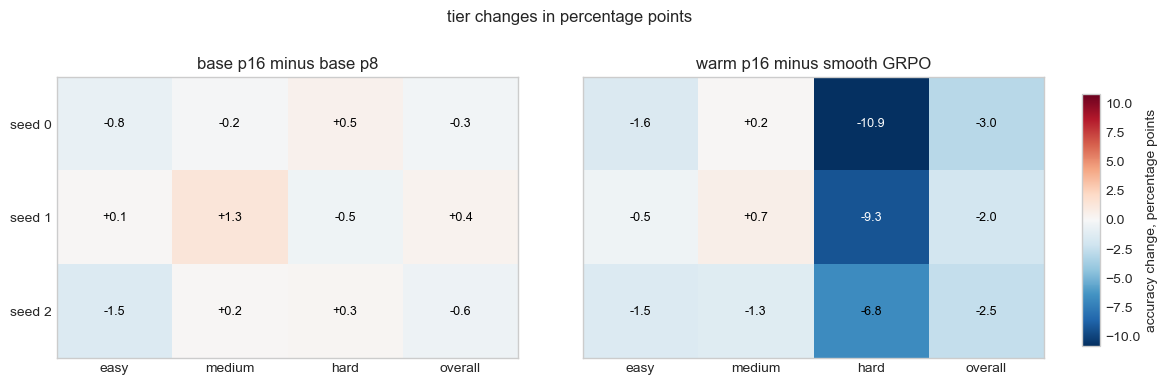

In [7]:
# locate the registered changes across tiers and seeds
tier_rows = []
for arm in REGISTERED['arms']:
    seed = arm['seed']
    for key, label in [
        ('base_budget', 'base p16 minus base p8'),
        ('warm_vs_smooth_grpo', 'warm p16 minus smooth GRPO'),
    ]:
        values = arm[key]
        for tier in TIERS:
            tier_rows.append({
                'comparison': label,
                'seed': seed,
                'group': tier,
                'delta': values['tiers'][tier]['new'] - values['tiers'][tier]['reference'],
            })
        tier_rows.append({
            'comparison': label,
            'seed': seed,
            'group': 'overall',
            'delta': values['delta'],
        })
tier_tbl = pd.DataFrame(tier_rows)
display(tier_tbl.pivot_table(
    index=['comparison', 'seed'],
    columns='group',
    values='delta',
)[GROUPS].round(4))

limit = max(abs(tier_tbl['delta'].min()), abs(tier_tbl['delta'].max())) * 100
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2), sharey=True)
for ax, comparison in zip(axes, comparisons):
    matrix = (
        tier_tbl.query('comparison == @comparison')
        .pivot(index='seed', columns='group', values='delta')
        .loc[list(SEEDS), GROUPS]
        .to_numpy() * 100
    )
    image = ax.imshow(
        matrix,
        cmap='RdBu_r',
        norm=TwoSlopeNorm(vmin=-limit, vcenter=0, vmax=limit),
        aspect='auto',
        interpolation='nearest',
    )
    ax.grid(False)
    for row in range(matrix.shape[0]):
        for col in range(matrix.shape[1]):
            color = heatmap_text_color(image, matrix[row, col])
            ax.text(
                col,
                row,
                f'{matrix[row, col]:+.1f}',
                ha='center',
                va='center',
                color=color,
                fontsize=9,
            )
    ax.set_xticks(np.arange(len(GROUPS)))
    ax.set_xticklabels(GROUPS)
    ax.set_yticks(np.arange(len(SEEDS)))
    ax.set_yticklabels([f'seed {seed}' for seed in SEEDS])
    ax.set_title(comparison)

fig.suptitle('tier changes in percentage points')
fig.subplots_adjust(left=0.09, right=0.88, bottom=0.15, top=0.82, wspace=0.14)
colorbar_ax = fig.add_axes([0.91, 0.18, 0.015, 0.60])
fig.colorbar(
    image,
    cax=colorbar_ax,
    label='accuracy change, percentage points',
)
save(fig, 'fig04_tier_effects')
plt.show()

## 5. Subject pattern

The subject matrices use the same colour scale. The final column is the mean change across seeds. Tier separators follow the validated subject mapping.

comparison                      base p16 minus base p8  \
tier   subject                                           
easy   high_school_psychology                   0.0000   
       marketing                               -0.0114   
       us_foreign_policy                       -0.0367   
hard   formal_logic                            -0.0079   
       high_school_mathematics                  0.0049   
medium business_ethics                         -0.0100   
       high_school_geography                    0.0051   
       philosophy                               0.0086   

comparison                      warm p16 minus smooth GRPO  
tier   subject                                              
easy   high_school_psychology                      -0.0147  
       marketing                                    0.0128  
       us_foreign_policy                           -0.0533  
hard   formal_logic                                 0.0635  
       high_school_mathematics                     -0.1617  
medium business_ethics                              0.0000  
       high_school_geography                        0.0051  
       philosophy                                  -0.0064

saved fig05_subject_effects


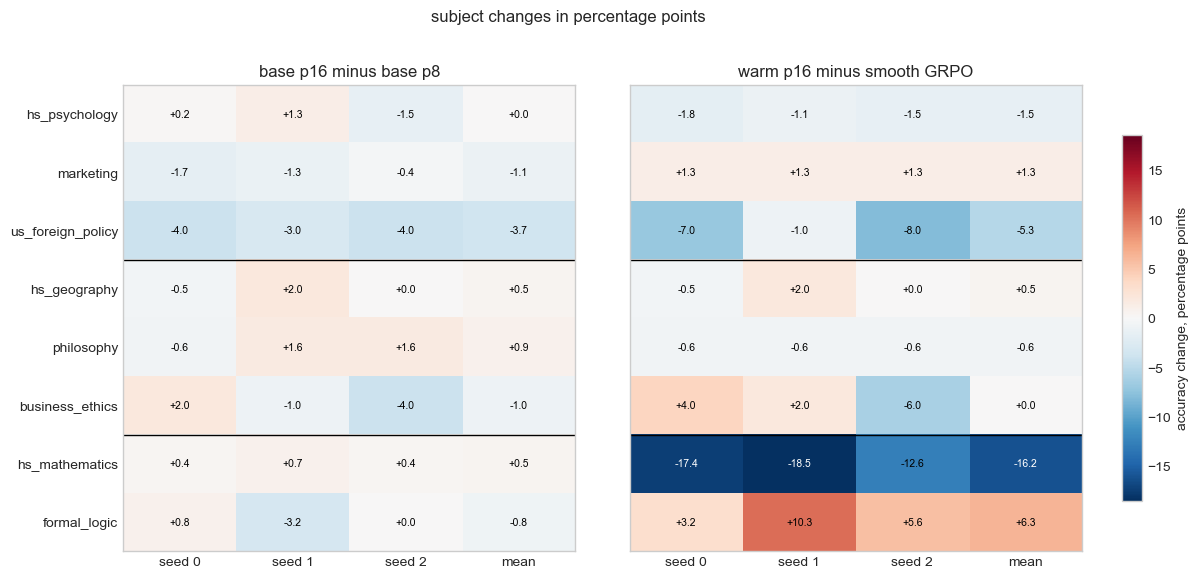

In [8]:
# compare subject changes for both registered questions
subject_rows = []
subject_specs = [
    (
        'base p16 minus base p8',
        REF['base p8'],
        NEW['base p16'],
    ),
    (
        'warm p16 minus smooth GRPO',
        REF['smooth GRPO'],
        NEW['warm p16'],
    ),
]

for comparison, reference_runs, new_runs in subject_specs:
    for seed in SEEDS:
        for subject in SUBJECTS:
            subject_rows.append({
                'comparison': comparison,
                'seed': seed,
                'subject': subject,
                'tier': TIER_LOOKUP[subject],
                'delta': (
                    new_runs[seed]['eval']['per_subject_acc'][subject]
                    - reference_runs[seed]['eval']['per_subject_acc'][subject]
                ),
            })
subject_tbl = pd.DataFrame(subject_rows)

subject_mean_tbl = (
    subject_tbl.groupby(['comparison', 'subject', 'tier'], as_index=False)['delta']
    .mean()
    .rename(columns={'delta': 'mean delta'})
)
display(subject_mean_tbl.pivot(
    index=['tier', 'subject'],
    columns='comparison',
    values='mean delta',
).round(4))

matrix_values = []
for comparison in comparisons:
    pivot = (
        subject_tbl.query('comparison == @comparison')
        .pivot(index='subject', columns='seed', values='delta')
        .loc[SUBJECTS, list(SEEDS)]
    )
    matrix_values.append(
        np.column_stack([pivot.to_numpy(), pivot.mean(axis=1)]) * 100
    )
subject_limit = max(abs(np.concatenate(matrix_values).min()), abs(np.concatenate(matrix_values).max()))

fig, axes = plt.subplots(1, 2, figsize=(13.5, 6.3), sharey=True)
for ax, comparison, matrix in zip(axes, comparisons, matrix_values):
    image = ax.imshow(
        matrix,
        cmap='RdBu_r',
        norm=TwoSlopeNorm(vmin=-subject_limit, vcenter=0, vmax=subject_limit),
        aspect='auto',
        interpolation='nearest',
    )
    ax.grid(False)
    for row in range(matrix.shape[0]):
        for col in range(matrix.shape[1]):
            color = heatmap_text_color(image, matrix[row, col])
            ax.text(
                col,
                row,
                f'{matrix[row, col]:+.1f}',
                ha='center',
                va='center',
                color=color,
                fontsize=7.5,
            )
    ax.set_xticks(np.arange(4))
    ax.set_xticklabels(['seed 0', 'seed 1', 'seed 2', 'mean'])
    ax.set_yticks(np.arange(len(SUBJECTS)))
    ax.set_yticklabels([
        subject.replace('high_school_', 'hs_')
        for subject in SUBJECTS
    ])
    easy_end = len(VALIDATED_TIERS['easy']) - 0.5
    medium_end = len(VALIDATED_TIERS['easy']) + len(VALIDATED_TIERS['medium']) - 0.5
    ax.axhline(easy_end, color='black', lw=1)
    ax.axhline(medium_end, color='black', lw=1)
    ax.set_title(comparison)

fig.suptitle('subject changes in percentage points')
fig.subplots_adjust(left=0.17, right=0.88, bottom=0.12, top=0.86, wspace=0.12)
colorbar_ax = fig.add_axes([0.91, 0.20, 0.015, 0.58])
fig.colorbar(
    image,
    cax=colorbar_ax,
    label='accuracy change, percentage points',
)
save(fig, 'fig05_subject_effects')
plt.show()

## 6. Paired item changes

The net score can hide how many questions changed in both directions. These panels count matched test items that only the reference answered correctly and items that only the new endpoint answered correctly.

reference only correct  new only correct  \
comparison                 seed                                             
base p16 minus base p8     0                         38                32   
                           1                         29                36   
                           2                         40                29   
warm p16 minus smooth GRPO 0                        138                82   
                           1                        130                93   
                           2                        138                90   

                                 net items  
comparison                 seed             
base p16 minus base p8     0            -6  
                           1             7  
                           2           -11  
warm p16 minus smooth GRPO 0           -56  
                           1           -37  
                           2           -48

saved fig06_paired_transitions


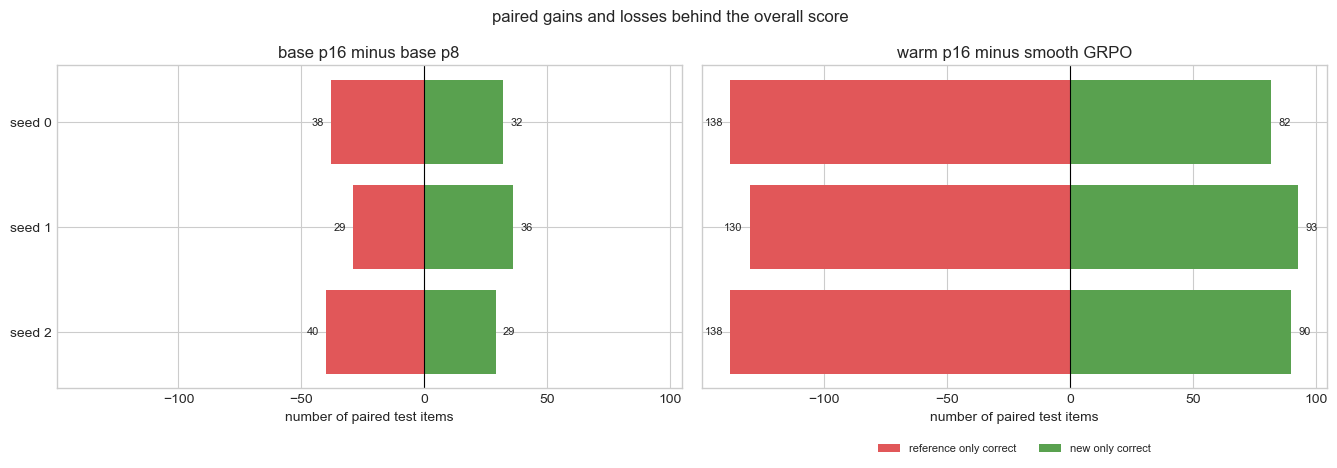

In [9]:
# count paired gains and losses behind each overall effect
transition_rows = []
paired_specs = [
    (
        'base p16 minus base p8',
        REF['base p8'],
        NEW['base p16'],
    ),
    (
        'warm p16 minus smooth GRPO',
        REF['smooth GRPO'],
        NEW['warm p16'],
    ),
]

for comparison, reference_runs, new_runs in paired_specs:
    for seed in SEEDS:
        reference_rows, new_rows = align_pred_rows(
            reference_runs[seed]['preds'],
            new_runs[seed]['preds'],
        )
        reference_correct = np.asarray([
            bool(row['correct']) for row in reference_rows
        ])
        new_correct = np.asarray([
            bool(row['correct']) for row in new_rows
        ])
        reference_only = int(np.sum(reference_correct & ~new_correct))
        new_only = int(np.sum(~reference_correct & new_correct))
        transition_rows.append({
            'comparison': comparison,
            'seed': seed,
            'reference only correct': reference_only,
            'new only correct': new_only,
            'net items': new_only - reference_only,
        })
transition_tbl = pd.DataFrame(transition_rows)
display(transition_tbl.set_index(['comparison', 'seed']))

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8), sharex=True, sharey=True)
for ax, comparison in zip(axes, comparisons):
    table = transition_tbl.query('comparison == @comparison').sort_values('seed')
    y = np.arange(len(table))
    losses = -table['reference only correct'].to_numpy()
    gains = table['new only correct'].to_numpy()
    ax.barh(y, losses, color='#E15759', label='reference only correct')
    ax.barh(y, gains, color='#59A14F', label='new only correct')
    for position, loss, gain in zip(y, -losses, gains):
        ax.text(-loss - 3, position, str(loss), ha='right', va='center', fontsize=8)
        ax.text(gain + 3, position, str(gain), ha='left', va='center', fontsize=8)
    ax.axvline(0, color='black', lw=0.8)
    ax.set_yticks(y)
    ax.set_yticklabels([f'seed {seed}' for seed in table['seed']])
    ax.set_xlabel('number of paired test items')
    ax.set_title(comparison)

axes[0].invert_yaxis()
axes[1].legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.14), ncol=2)
fig.suptitle('paired gains and losses behind the overall score')
fig.tight_layout()
save(fig, 'fig06_paired_transitions')
plt.show()

## 7. Probe and generative behaviour

The letter probe is separate from free generation. Stable probe accuracy with a different generative score is evidence about elicitation under this protocol, not proof that factual knowledge was added or removed.

,,delta,ci low,ci high,classification
condition,seed,,,,
base p16,0,-0.001592,-0.009554,0.006369,unchanged
warm p16,0,-0.000531,-0.009554,0.008493,unchanged
base p16,1,-0.002654,-0.010616,0.005839,unchanged
warm p16,1,0.001592,-0.006369,0.009554,unchanged
base p16,2,0.001592,-0.005852,0.009554,unchanged
warm p16,2,-0.002654,-0.011146,0.005839,unchanged


,,hard generative,hard probe,hard margin
condition,seed,,,
base p16,0,0.5581,0.5758,-0.0177
warm p16,0,0.5328,0.5556,-0.0227
base p16,1,0.5379,0.5707,-0.0328
warm p16,1,0.5455,0.5808,-0.0354
base p16,2,0.5606,0.5783,-0.0177
warm p16,2,0.5480,0.5581,-0.0101


saved fig07_probe_and_generation


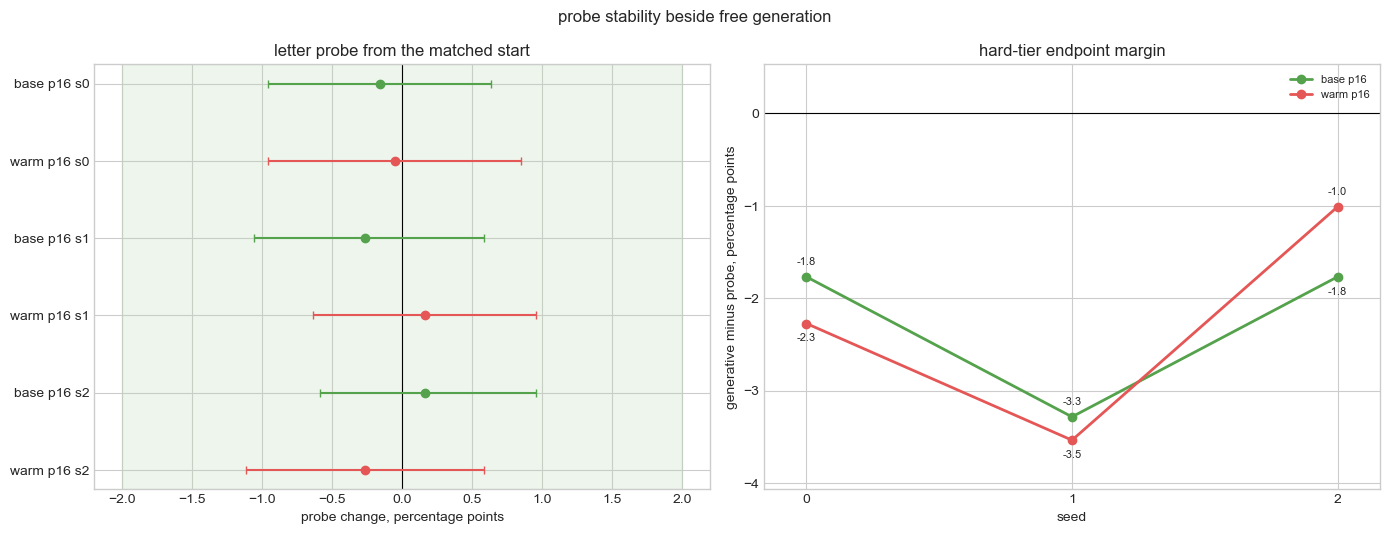

In [10]:
# compare probe changes from each start and hard generative margins
probe_rows = []
margin_rows = []
for arm in REGISTERED['arms']:
    seed = arm['seed']
    for key, label in [
        ('base_probe_from_start', 'base p16'),
        ('warm_probe_from_start', 'warm p16'),
    ]:
        values = arm[key]
        probe_rows.append({
            'condition': label,
            'seed': seed,
            'delta': values['delta'],
            'ci low': values['ci'][0],
            'ci high': values['ci'][1],
            'classification': values['classification'],
        })
    for endpoint, label in [
        ('base_p16', 'base p16'),
        ('warm_p16', 'warm p16'),
    ]:
        values = arm['endpoints'][endpoint]
        margin_rows.append({
            'condition': label,
            'seed': seed,
            'hard generative': values['hard_acc'],
            'hard probe': values['hard_probe'],
            'hard margin': values['hard_margin'],
        })

probe_tbl = pd.DataFrame(probe_rows)
margin_tbl = pd.DataFrame(margin_rows)
display(probe_tbl.set_index(['condition', 'seed']).round(6))
display(margin_tbl.set_index(['condition', 'seed']).round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.4))
probe_plot = probe_tbl.copy()
probe_plot['label'] = probe_plot.apply(
    lambda row: f"{row['condition']} s{row['seed']}",
    axis=1,
)
y = np.arange(len(probe_plot))
values = probe_plot['delta'].to_numpy() * 100
errors = np.vstack([
    values - probe_plot['ci low'].to_numpy() * 100,
    probe_plot['ci high'].to_numpy() * 100 - values,
])
point_colors = [COLORS[value] for value in probe_plot['condition']]
axes[0].axvspan(-2, 2, color='#B9D8B4', alpha=0.25)
axes[0].axvline(0, color='black', lw=0.8)
for position, value, error, color in zip(y, values, errors.T, point_colors):
    axes[0].errorbar(
        value,
        position,
        xerr=np.asarray(error).reshape(2, 1),
        fmt='o',
        capsize=3,
        color=color,
    )
axes[0].set_yticks(y)
axes[0].set_yticklabels(probe_plot['label'])
axes[0].invert_yaxis()
axes[0].set_xlabel('probe change, percentage points')
axes[0].set_title('letter probe from the matched start')

for condition in ['base p16', 'warm p16']:
    table = margin_tbl.query('condition == @condition').sort_values('seed')
    axes[1].plot(
        table['seed'],
        table['hard margin'] * 100,
        marker='o',
        lw=2,
        color=COLORS[condition],
        label=condition,
    )
    for seed, value in zip(table['seed'], table['hard margin'] * 100):
        above = value == margin_tbl.loc[margin_tbl['seed'] == seed, 'hard margin'].max() * 100
        axes[1].annotate(
            f'{value:+.1f}', (seed, value), xytext=(0, 7 if above else -7),
            textcoords='offset points', ha='center', va='bottom' if above else 'top',
            fontsize=8,
        )
axes[1].margins(x=0.08, y=0.15)
axes[1].axhline(0, color='black', lw=0.8)
axes[1].set_xticks(SEEDS)
axes[1].set_xlabel('seed')
axes[1].set_ylabel('generative minus probe, percentage points')
axes[1].set_title('hard-tier endpoint margin')
axes[1].legend(fontsize=8)

fig.suptitle('probe stability beside free generation')
fig.tight_layout()
save(fig, 'fig07_probe_and_generation')
plt.show()

## 8. Warm p8 comparison

This is not a three seed matched budget test. Seed 0 is the only exact preparation match because the earlier 015 seeds all started from the seed 0 GSM8K-SFT checkpoint. Seeds 1 and 2 are shown as open points for context only.

,reference,new,delta,ci low,ci high,raw p,exact preparation
seed,,,,,,,
0,0.773885,0.778132,0.004246,-0.002123,0.010616,0.242985,True
1,0.776539,0.781847,0.005308,-0.002123,0.012739,0.202639,False
2,0.779724,0.772293,-0.007431,-0.015924,0.001062,0.108857,False


saved fig08_warm_budget_descriptive


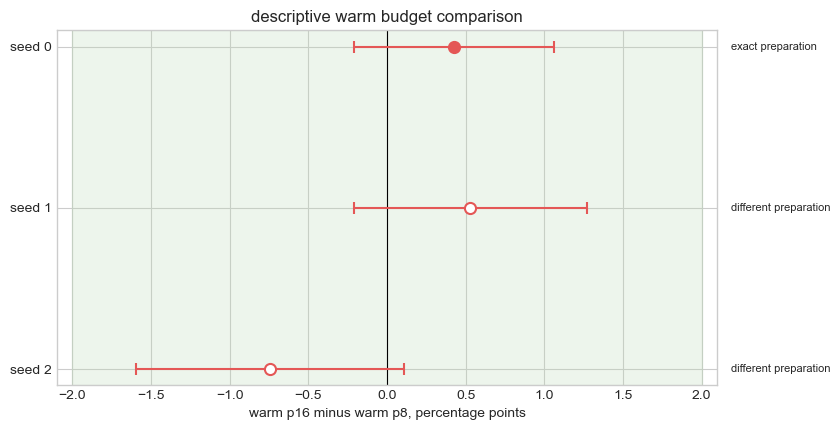

In [11]:
# keep the warm budget comparison separate from the binding results
warm_rows = []
for arm in REGISTERED['arms']:
    seed = arm['seed']
    values = arm['warm_budget_descriptive']
    warm_rows.append({
        'seed': seed,
        'reference': values['reference_acc'],
        'new': values['new_acc'],
        'delta': values['delta'],
        'ci low': values['ci'][0],
        'ci high': values['ci'][1],
        'raw p': values['p_raw'],
        'exact preparation': values['exact_preparation_match'],
    })
warm_tbl = pd.DataFrame(warm_rows)
display(warm_tbl.set_index('seed').round(6))

fig, ax = plt.subplots(figsize=(8.5, 4.4))
y = np.arange(len(warm_tbl))
values = warm_tbl['delta'].to_numpy() * 100
errors = np.vstack([
    values - warm_tbl['ci low'].to_numpy() * 100,
    warm_tbl['ci high'].to_numpy() * 100 - values,
])
ax.axvspan(-2, 2, color='#B9D8B4', alpha=0.25)
ax.axvline(0, color='black', lw=0.8)
for position, (_, row), error in zip(y, warm_tbl.iterrows(), errors.T):
    face = COLORS['warm p16'] if row['exact preparation'] else 'white'
    ax.errorbar(
        row['delta'] * 100,
        position,
        xerr=np.asarray(error).reshape(2, 1),
        fmt='o',
        capsize=4,
        color=COLORS['warm p16'],
        markerfacecolor=face,
        markeredgewidth=1.5,
        markersize=8,
    )
    match = 'exact preparation' if row['exact preparation'] else 'different preparation'
    ax.text(1.02, position, match, transform=ax.get_yaxis_transform(),
            va='center', fontsize=8)
ax.set_yticks(y)
ax.set_yticklabels([f'seed {seed}' for seed in warm_tbl['seed']])
ax.invert_yaxis()
ax.set_xlim(-2.1, 2.1)
ax.set_xlabel('warm p16 minus warm p8, percentage points')
ax.set_title('descriptive warm budget comparison')
fig.tight_layout()
save(fig, 'fig08_warm_budget_descriptive')
plt.show()

## 9. Exact values

The tables below are saved beside the figures so the plotted values can be reused without reading them from the image.

In [12]:
# save the exact values used by the figures
effect_tbl.to_csv(FIG / '024_1_registered_effects.csv', index=False)
endpoint_tbl.to_csv(FIG / '024_1_endpoints.csv', index=False)
tier_tbl.to_csv(FIG / '024_1_tier_effects.csv', index=False)
subject_tbl.to_csv(FIG / '024_1_subject_effects.csv', index=False)
transition_tbl.to_csv(FIG / '024_1_paired_transitions.csv', index=False)
probe_tbl.to_csv(FIG / '024_1_probe_effects.csv', index=False)
warm_tbl.to_csv(FIG / '024_1_warm_budget_descriptive.csv', index=False)

headline = effect_tbl.copy()
headline['reference'] = (headline['reference'] * 100).round(2)
headline['new'] = (headline['new'] * 100).round(2)
headline['delta'] = (headline['delta'] * 100).round(2)
headline['95% interval'] = effect_tbl.apply(
    lambda row: f"[{row['ci low'] * 100:+.2f}, {row['ci high'] * 100:+.2f}]",
    axis=1,
)
display(headline[[
    'comparison',
    'seed',
    'reference',
    'new',
    'delta',
    '95% interval',
    'Holm p',
    'classification',
]].set_index(['comparison', 'seed']))

print('saved exact tables ->', FIG)

,,reference,new,delta,95% interval,Holm p,classification
comparison,seed,,,,,,
base p16 minus base p8,0,78.61,78.29,-0.32,"[-1.17, +0.53]",0.914042,equivalent
warm p16 minus smooth GRPO,0,80.79,77.81,-2.97,"[-4.51, -1.43]",0.000583,material decline
base p16 minus base p8,1,78.03,78.40,0.37,"[-0.48, +1.22]",0.914042,equivalent
warm p16 minus smooth GRPO,1,80.15,78.18,-1.96,"[-3.56, -0.42]",0.015730,inconclusive
base p16 minus base p8,2,78.45,77.87,-0.58,"[-1.43, +0.32]",0.685201,equivalent
warm p16 minus smooth GRPO,2,79.78,77.23,-2.55,"[-4.09, -0.96]",0.003584,material decline


saved exact tables -> /Users/oleggastov/Desktop/University UK/0006_City n St Georges Universities/003_Projects/INM363-IndividualProject-Dissertation/001_Code/analysis/figures/024_1


## Cross-referenced conclusion

All six 024 arms completed cleanly on A100 80GB with the declared p16 configuration. The schedules covered all 245 steps, evaluation used 1,884 items per mode, format compliance was 1.0 and no fallback was used.

Doubling base MC-SFT from p8 to p16 did not improve the result. All three matched seeds were classified as equivalent, with changes from -0.6 to +0.4 percentage points. This is strong evidence that the base supervised route was already near its useful budget at p8 under this training recipe.

Warm p16 also did not catch the seed matched smooth 1000 step GRPO endpoints. Seeds 0 and 2 were material declines of 3.0 and 2.5 points. Seed 1 declined by 2.0 points but remained inconclusive under the binding Holm rule. The registered common reading stays mixed or inconclusive and must be reported arm by arm, although all three point estimates favour smooth GRPO.

The largest warm route gap was on the hard tier: -10.9, -9.3 and -6.8 points across the three seeds. Probe changes from both starts were classified as unchanged, so the generative difference is not matched by clear change in letter-probe accuracy.

The warm p8 to p16 result cannot be treated as a three seed budget comparison. Only seed 0 is preparation matched, where the change was +0.4 points and its interval crossed zero. The 024 result is also method as practised because p8 and p16 each used their own linear decay schedule.